# Train the CDSS risk models (CVD, T2D, CRD, NEURO)

Follows the **Machine Learning Plan: CDSS Risk Models** (Nov 4, 2026). Same style as the synthetic notebooks: **CODE → TEST → RUN**, fixed seed.

- Data: `ml/synthetic/output/` from Notebook 1 (and `ml/synthetic/output_seed2/` for the external check, when it exists).
- Features: `ml/features.yaml`, the same file the app reads, in the same order.
- Split 70 / 15 / 15, stratified, one patient in one part only. 5-fold CV on train only. Choose by AUPRC.
- Output: **one `.joblib` per disease** in `ml/artifacts/` (CalibratedClassifierCV with XGBoost inside), as agreed with Costin, so `backend/model_registry.py` can load it. Plus `metrics.csv`, `model_card.md` and `register_models.sql`.

**Run:** `uv sync --group ml`, then `uv run jupyter lab ml/ai_model/train_models.ipynb`, then *Restart and Run All*.

> **Phase 0 first.** On the current synthetic data the AUROC is close to 1.00 (Section 1 of the ML Plan). This notebook will then mark the results `LEAK?`. That is expected until Notebook 1 gets the partial, noisy early signal. Do not register models trained before Phase 0.

## Cell 0 — Setup

In [1]:
import hashlib, json, sys, warnings
from datetime import date, datetime
from importlib import metadata
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import xgboost as xgb
import yaml
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    import mlflow                     # in the "ml" dependency group: uv sync --group ml
    HAS_MLFLOW = True
except ImportError:
    HAS_MLFLOW = False

SEED = 20261101                       # same seed as Notebook 1
DISEASES = ["CVD", "T2D", "CRD", "NEURO"]
PLATT_FOR = {"NEURO"}                 # few positives -> Platt (sigmoid) instead of isotonic
N_BOOT = 1000

# ml/ = the folder with features.yaml (the notebook runs from ml/ai_model/)
ML = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "features.yaml").exists())
ROOT = ML.parent
sys.path.insert(0, str(ROOT))         # to load the saved files with the app's own code in Cell 8
DATA = ML / "synthetic" / "output"
DATA2 = ML / "synthetic" / "output_seed2"     # Notebook 1 again with another seed (external check)
ART = ML / "artifacts"
SPEC = yaml.safe_load((ML / "features.yaml").read_text(encoding="utf-8"))
TIER_CUTS = (0.20, 0.50)              # = risk_tiers in features.yaml (Data Dictionary)

# training.csv from Notebook 1: patient_id, domain, index_date, label (index_date = first visit)
TRAIN_COLS = {"patient": "patient_id", "disease": "domain", "label": "label"}
LABEL_COL = {d: f"y_{d}" for d in DISEASES}

# Notebook 1 column name -> features.yaml name (the app uses the features.yaml names)
SOURCE_NAMES = {
    "heart_rate": "resting_hr", "sodium_mg": "sodium_mg_day", "activity_min_week": "physical_activity_min_week",
    "pg_2h": "ogtt_2h", "carbs_g": "carbs_g_day", "sedentary_hours": "sedentary_hours_day",
    "sleep_hours": "sleep_hours_day", "fhrs_CVD": "fhrs_cvd", "fhrs_T2D": "fhrs_t2d",
    "fhrs_CRD": "fhrs_crd", "fhrs_NEURO": "fhrs_neuro",
}

# Expected direction (ML Plan, Section 4): +1 higher -> higher risk, -1 higher -> lower risk.
# Used as XGBoost monotone constraints and for the Cell 7 direction test.
EXPECTED_DIR = {
    "CVD":   {"sbp": 1, "ldl": 1, "pack_years": 1, "age": 1, "fhrs_cvd": 1, "hdl": -1, "physical_activity_min_week": -1,
              "smoking_status": 1},
    "T2D":   {"hba1c": 1, "fpg": 1, "bmi": 1, "waist_cm": 1, "fhrs_t2d": 1,
              "smoking_status": 1},
    "CRD":   {"pack_years": 1, "eosinophils": 1, "spo2": -1,
              "fhrs_crd": 1, "smoking_status": 1},
    "NEURO": {"phq9": 1, "gad7": 1, "psqi": 1, "fhrs_neuro": 1},   # sleep: "very short" is not a straight line
}

VERSIONS = {p: metadata.version(p) for p in ("xgboost", "scikit-learn", "numpy", "pandas", "joblib")}
print(f"ml folder: {ML}\nfeatures.yaml v{SPEC.get('version')} ({SPEC.get('status')})")
print("packages:", VERSIONS, "| mlflow:", HAS_MLFLOW)

/home/nirmata/Desktop/thesis-d3/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/06 15:20:09 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/nirmata/Desktop/thesis-d3/.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


ml folder: /home/nirmata/Desktop/thesis-d3/ml
features.yaml v1 (draft, waiting for group approval)
packages: {'xgboost': '3.2.0', 'scikit-learn': '1.9.1', 'numpy': '2.4.6', 'pandas': '3.1.0', 'joblib': '1.6.0'} | mlflow: True


## Cell 1 — Load: first visit + features.yaml → one table per model

In [2]:
# ---------- CODE ----------
def feature_names(spec, d):
    return [f["name"] for f in spec["models"][d]["features"]]

def all_features(spec):
    out = {}
    for d in DISEASES:
        for f in spec["models"][d]["features"]:
            out.setdefault(f["name"], f)
    return out

def required(spec, d):
    return [f["name"] for f in spec["models"][d]["features"] if f.get("required")]

def directions(spec, d):
    return [EXPECTED_DIR[d].get(n, 0) for n in feature_names(spec, d)]

FORBIDDEN_EXACT = {"has_CVD", "has_CV_event", "has_HTN", "has_T2D", "has_T2D_any", "has_CRD", "has_NEURO", "t2d_diagnosed",
                   "patient_id", "visit_date", "visit_no", *LABEL_COL.values()}
FORBIDDEN_PREFIX = ("true_dx_year_", "fhrs_band_")

def is_forbidden(col):
    return col in FORBIDDEN_EXACT or col.startswith(FORBIDDEN_PREFIX)

def encode(df, spec):
    """Text -> number with each feature's `encoding` in features.yaml (sex: Male 1, Female 0)."""
    df = df.copy()
    for name, f in all_features(spec).items():
        if "encoding" in f and name in df:
            df[name] = df[name].map(lambda x: f["encoding"].get(x, np.nan) if pd.notna(x) else np.nan)
    return df

def load_tables(folder, spec):
    """{disease: (X, y, patient_id)} from the FIRST visit only."""
    tr = pd.read_csv(folder / "training.csv")
    missing = [c for c in TRAIN_COLS.values() if c not in tr]
    assert not missing, f"training.csv has no column {missing}; it has {list(tr.columns)}"
    assert set(tr[TRAIN_COLS["disease"]]) <= set(DISEASES), "unknown disease in training.csv"
    assert not tr.duplicated([TRAIN_COLS["patient"], TRAIN_COLS["disease"]]).any(), "patient twice for one disease"
    lab = (tr.pivot(index=TRAIN_COLS["patient"], columns=TRAIN_COLS["disease"], values=TRAIN_COLS["label"])
             .rename(columns=LABEL_COL).rename_axis(None, axis=1).reset_index())
    vis = pd.read_csv(folder / "visits.csv").rename(columns=SOURCE_NAMES)
    first = vis[vis.visit_no == 1]
    assert first.patient_id.is_unique, "more than one first visit for a patient"
    index_dates = tr.groupby(TRAIN_COLS["patient"])["index_date"].first()
    assert (first.set_index("patient_id").visit_date.reindex(index_dates.index) == index_dates).all(), \
        "index_date must be the first visit"
    df = lab.merge(first.drop(columns=["visit_no", "visit_date"]), on="patient_id", how="left")
    pat = pd.read_csv(folder / "patients.csv").rename(columns=SOURCE_NAMES)
    keep = ["patient_id"] + [c for c in pat if c not in df and not is_forbidden(c)]
    df = encode(df.merge(pat[keep], on="patient_id", how="left"), spec)
    out = {}
    for d in DISEASES:
        cols = feature_names(spec, d)
        missing = [c for c in cols if c not in df]
        assert not missing, f"{d}: features.yaml names not in the data: {missing} (add them to SOURCE_NAMES?)"
        sub = df[df[LABEL_COL[d]].notna()]                     # already-ill patients have no row
        out[d] = (sub[cols].astype(float).reset_index(drop=True), sub[LABEL_COL[d]].astype(int).to_numpy(),
                  sub.patient_id.to_numpy())
    return out

def out_of_range(X, spec, d):
    bad = {}
    for f in spec["models"][d]["features"]:
        r = f.get("range")
        if not r:
            continue
        lo = r[0] if r[0] is not None else -np.inf
        hi = r[1] if r[1] is not None else np.inf
        k = int(((X[f["name"]] < lo) | (X[f["name"]] > hi)).sum())
        if k:
            bad[f["name"]] = k
    return bad

# ---------- TEST ----------
def test_load(tables, spec):
    for d, (X, y, pid) in tables.items():
        assert not [c for c in X.columns if is_forbidden(c)], f"{d}: forbidden column"
        assert list(X.columns) == feature_names(spec, d), f"{d}: order differs from features.yaml"
        assert set(np.unique(y)) <= {0, 1} and len(set(pid)) == len(pid)
        assert not out_of_range(X, spec, d), f"{d}: values outside the features.yaml range: {out_of_range(X, spec, d)}"
        assert X["sex"].isin([0, 1]).all() if "sex" in X else True, f"{d}: sex not encoded"
        blanks = {c: int(X[c].isna().sum()) for c in required(spec, d) if X[c].isna().any()}
        if blanks:
            print(f"  NOTE {d}: required features with blanks: {blanks}")
    for d in DISEASES:
        extra = set(EXPECTED_DIR[d]) - set(feature_names(spec, d))
        assert not extra, f"{d}: EXPECTED_DIR names not in features.yaml: {extra}"
    print("TEST Cell 1: PASS")

# ---------- RUN ----------
TABLES = load_tables(DATA, SPEC)
test_load(TABLES, SPEC)
pd.DataFrame({d: {"features": X.shape[1], "rows": len(y), "positives": int(y.sum()), "label rate": f"{y.mean():.1%}"}
              for d, (X, y, _) in TABLES.items()}).T

TEST Cell 1: PASS


,features,rows,positives,label rate
CVD,18,16556,971,5.9%
T2D,19,17270,606,3.5%
CRD,15,17744,573,3.2%
NEURO,11,18727,240,1.3%


## Cell 2 — Split 70 / 15 / 15 (stratified, by patient). The test part is touched once, in Cell 6.

In [3]:
# ---------- CODE ----------
def split(X, y, pid, seed=SEED):
    idx = np.arange(len(y))
    tr, rest = train_test_split(idx, test_size=0.30, stratify=y, random_state=seed)
    va, te = train_test_split(rest, test_size=0.50, stratify=y[rest], random_state=seed)
    return {k: (X.iloc[i].reset_index(drop=True), y[i], pid[i]) for k, i in [("train", tr), ("val", va), ("test", te)]}

# ---------- TEST ----------
def test_split(parts, d):
    ids = [set(parts[k][2]) for k in ("train", "val", "test")]
    assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]), f"{d}: patient in two parts"
    assert (split(*TABLES[d])["test"][2] == parts["test"][2]).all(), f"{d}: same seed must give the same split"
    assert all(parts[k][1].sum() > 0 for k in parts), f"{d}: a part has no positives"

# ---------- RUN ----------
SPLITS = {d: split(*TABLES[d]) for d in DISEASES}
for d in DISEASES:
    test_split(SPLITS[d], d)
print("TEST Cell 2: PASS")
pd.DataFrame({d: {k: f"{len(v[1])} ({v[1].sum()} pos)" for k, v in s.items()} for d, s in SPLITS.items()}).T

TEST Cell 2: PASS


,train,val,test
CVD,11589 (680 pos),2483 (145 pos),2484 (146 pos)
T2D,12089 (424 pos),2590 (91 pos),2591 (91 pos)
CRD,12420 (401 pos),2662 (86 pos),2662 (86 pos)
NEURO,13108 (168 pos),2809 (36 pos),2810 (36 pos)


## Cell 3 — Baseline: logistic regression (scaled; blanks = median + a "was missing" flag; `class_weight="balanced"`)

In [4]:
# ---------- CODE ----------
def fit_baseline(X, y):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(class_weight="balanced", max_iter=2000)).fit(X, y)

# ---------- RUN ----------
BASE = {}
for d in DISEASES:
    (Xtr, ytr, _), (Xva, yva, _) = SPLITS[d]["train"], SPLITS[d]["val"]
    BASE[d] = fit_baseline(Xtr, ytr)
    pv = BASE[d].predict_proba(Xva)[:, 1]
    print(f"{d:5s} baseline  val AUROC {roc_auc_score(yva, pv):.3f}  AUPRC {average_precision_score(yva, pv):.3f}")

CVD   baseline  val AUROC 0.735  AUPRC 0.168
T2D   baseline  val AUROC 0.680  AUPRC 0.096


CRD   baseline  val AUROC 0.719  AUPRC 0.117
NEURO baseline  val AUROC 0.621  AUPRC 0.020


## Cell 4 — XGBoost: Optuna on the shared folds, early stopping on held-out rows, choose by AUPRC
`scale_pos_weight` = negatives ÷ positives (no SMOTE). Monotone constraints from `EXPECTED_DIR`. XGBoost is the model for all four diseases (group decision, Nov 7, 2026: right directions, TreeSHAP, Chapter 3). The baseline stays as a comparison row in Cell 6.

**Tuning (G7, #52):** Optuna, the same code as candidate (b) of the evaluation protocol (`ml/investigate/optuna_candidate.py`):
- folds: 3 repeats × 5 folds of **train only** (`evaluation_protocol.make_folds`, the rule behind `shared_splits.csv`); settings are chosen on **repeats 1 and 2** only;
- early stopping on the **stopping rows held out from each training fold**, never on the scored fold;
- score: **AUPRC** only (mean over folds);
- TPE sampler (fixed seed) + MedianPruner, `oc.N_TRIALS` trials per disease; trial 1 is the old default (depth 3, learning rate 0.1);
- the refit on all of train uses the mean tree count of the tuning folds.

Validation and test are never used here (`Task.check` guards every fit). Every trial is saved to `ml/artifacts/optuna_<disease>.csv`.

In [ ]:
# ---------- CODE ----------
sys.path.insert(0, str(ML / "investigate"))
import evaluation_protocol as ep        # folds, leakage guard, early stopping on held-out rows
import optuna_candidate as oc            # the Optuna search: the same code the group compared against the grid
MAX_TREES, EARLY = ep.MAX_TREES, ep.EARLY

def tune_gbm(d, train, val, mono, n_trials=oc.N_TRIALS):
    """train, val: (X, y, patient_id). Returns (refit on all of train, settings, trees, scale_pos_weight, study)."""
    task = ep.Task(d, train, val, mono)
    folds = ep.make_folds(train[2], train[1]).assign(disease=d)
    params, study = oc.tune(task, folds, n_trials)
    n_trees = int(study.best_trial.user_attrs["n_trees"])
    spw = (train[1] == 0).sum() / max(1, (train[1] == 1).sum())
    return task.fit_final(params, n_trees), params, n_trees, spw, study

# ---------- TEST ----------
def test_tuning(d, model, params, study, mono):
    for k, (kind, lo, hi) in oc.SPACE.items():
        assert lo <= params[k] <= hi, f"{d}: {k}={params[k]} outside {lo}-{hi}"
    first = study.trials[0]
    assert first.params == oc.DEFAULT, f"{d}: trial 1 must be the old default"
    assert study.best_value >= first.value, f"{d}: Optuna result worse than the old default on the tuning folds"
    assert tuple(model.get_params()["monotone_constraints"]) == tuple(mono), f"{d}: monotone constraints lost"

# ---------- RUN ----------
GBM, CHOSEN, PARAMS, TUNING = {}, {}, {}, []
ART.mkdir(exist_ok=True)
for d in DISEASES:
    (Xva, yva, _) = SPLITS[d]["val"]
    mono = directions(SPEC, d)
    GBM[d], params, n_trees, spw, study = tune_gbm(d, SPLITS[d]["train"], SPLITS[d]["val"], mono)
    test_tuning(d, GBM[d], params, study, mono)
    study.trials_dataframe().to_csv(ART / f"optuna_{d}.csv", index=False)
    PARAMS[d] = {**{k: round(v, 4) for k, v in params.items()}, "n_estimators": n_trees, "scale_pos_weight": round(float(spw), 3)}
    TUNING.append({"disease": d, "trials": len(study.trials),
                   "pruned": sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials),
                   "tune_auprc_old_default": study.trials[0].value, "tune_auprc_best": study.best_value,
                   "best_trial": study.best_trial.number + 1})
    ap_g = average_precision_score(yva, GBM[d].predict_proba(Xva)[:, 1])
    ap_b = average_precision_score(yva, BASE[d].predict_proba(Xva)[:, 1])
    CHOSEN[d] = "xgboost"
    print(f"{d:5s} {PARAMS[d]} | val AUPRC xgb {ap_g:.3f} vs baseline {ap_b:.3f} -> {CHOSEN[d]}")
print("TEST Cell 4: PASS")
pd.DataFrame(TUNING).round(4)

## Cell 5 — Calibration on validation (so 0.30 really means about 30 in 100) + risk tiers
`CalibratedClassifierCV(FrozenEstimator(model))`: the trained model is not changed; only the calibrator is fitted on validation. Isotonic, or Platt (sigmoid) for NEURO.

> **Note:** the calibrator is fitted on validation and the plot below is on that same data, so it looks better than it is. The honest check is the **test** calibration slope and Brier score in Cell 6.

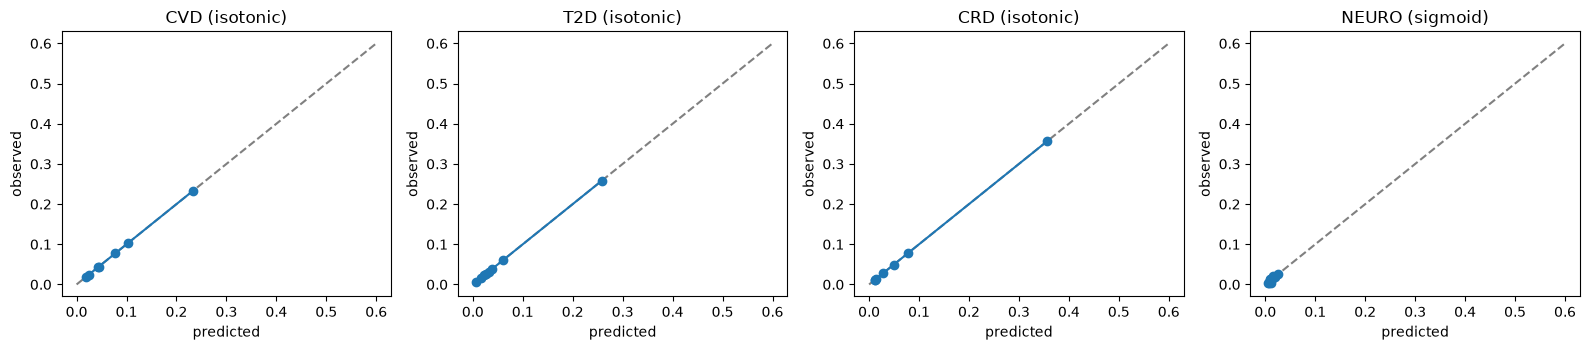

TEST Cell 5: PASS (plot = validation, which the calibrator was fitted on; see the test slope in Cell 6)


In [6]:
# ---------- CODE ----------
def chosen_model(d):
    return GBM[d] if CHOSEN[d] == "xgboost" else BASE[d]

def method_for(d):
    return "sigmoid" if d in PLATT_FOR else "isotonic"

def calibrate(model, X, y, d, method=None):
    method = method or method_for(d)
    return CalibratedClassifierCV(FrozenEstimator(model), method=method).fit(X, y)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def calib_slope(y, p):
    return LogisticRegression(C=1e6, max_iter=1000).fit(logit(p)[:, None], y).coef_[0, 0]

def tier(p):
    lo, hi = TIER_CUTS
    return "High" if p >= hi else "Moderate" if p >= lo else "Low"

def proba(d, X):
    return CAL[d].predict_proba(X)[:, 1]

# ---------- TEST ----------
assert tier(0.1999) == "Low" and tier(0.20) == "Moderate" and tier(0.4999) == "Moderate" and tier(0.50) == "High"
assert TIER_CUTS == (0.20, 0.50), "tier cut points must match the Data Dictionary"

# ---------- RUN ----------
CAL = {}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, d in zip(axes, DISEASES):
    Xva, yva, _ = SPLITS[d]["val"]
    CAL[d] = calibrate(chosen_model(d), Xva, yva, d)
    p = proba(d, Xva)
    assert ((p >= 0) & (p <= 1)).all()
    g = pd.DataFrame({"p": p, "y": yva}).groupby(pd.qcut(p, 10, duplicates="drop"), observed=True).mean()
    ax.plot([0, .6], [0, .6], "--", c="grey"); ax.plot(g.p, g.y, "o-")
    ax.set_title(f"{d} ({'sigmoid' if d in PLATT_FOR else 'isotonic'})"); ax.set_xlabel("predicted"); ax.set_ylabel("observed")
plt.tight_layout(); plt.show()

# Isotonic vs sigmoid for each XGBoost, on test. For the group only: the method in use does not change here.
rows_c = []
for d in DISEASES:
    (Xva, yva, _), (Xte, yte, _) = SPLITS[d]["val"], SPLITS[d]["test"]
    for method in ("isotonic", "sigmoid"):
        p = calibrate(GBM[d], Xva, yva, d, method).predict_proba(Xte)[:, 1]
        tiers = pd.Series([tier(x) for x in p]).value_counts()
        rows_c.append({"disease": d, "method": method, "in_use": method == method_for(d), "calib_slope": calib_slope(yte, p),
                       "brier": brier_score_loss(yte, p), "auroc": roc_auc_score(yte, p), "max_p": p.max(),
                       **{t: int(tiers.get(t, 0)) for t in ("Low", "Moderate", "High")}})
print(pd.DataFrame(rows_c).round(3).to_string(index=False))
print("TEST Cell 5: PASS (plot = validation, which the calibrator was fitted on; see the test slope in Cell 6)")

## Cell 6 — Evaluate on test (and on the second-seed data), 95% bootstrap, 1,000 resamples
Targets were written **before** training (ML Plan, Section 4): AUROC 0.70–0.90 (above 0.90 = check for leakage), AUPRC clearly above the label rate, Brier below the baseline's, calibration slope 0.8–1.2.

In [7]:
# ---------- CODE ----------
def boot_ci(y, p, fn, n=N_BOOT, seed=SEED):
    rng, vals = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            vals.append(fn(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

def at_cut(y, p, cut):
    tn, fp, fn, tp = confusion_matrix(y, (p >= cut).astype(int), labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else np.nan
    return {"sens": div(tp, tp + fn), "spec": div(tn, tn + fp), "ppv": div(tp, tp + fp), "npv": div(tn, tn + fn)}

def evaluate(d, X, y, where, baseline=False):
    p_base = calibrate(BASE[d], *SPLITS[d]["val"][:2], d).predict_proba(X)[:, 1]
    p = p_base if baseline else proba(d, X)
    r = {"disease": d, "data": where, "model": "baseline" if baseline else CHOSEN[d], "n": len(y), "pos": int(y.sum()), "label_rate": y.mean()}
    for name, fn in [("auroc", roc_auc_score), ("auprc", average_precision_score), ("brier", brier_score_loss)]:
        lo, hi = boot_ci(y, p, fn)
        r[name], r[f"{name}_ci"] = fn(y, p), f"{lo:.2f}-{hi:.2f}"
    r["brier_baseline"] = brier_score_loss(y, p_base)
    r["calib_slope"] = calib_slope(y, p)
    for cut in TIER_CUTS:
        r.update({f"{k}@{cut}": v for k, v in at_cut(y, p, cut).items()})
    shares = pd.Series([tier(x) for x in p]).value_counts(normalize=True)
    for t in ("Low", "Moderate", "High"):
        r[f"share_{t}"] = shares.get(t, 0.0)
    r["auroc_flag"] = "LEAK?" if r["auroc"] > 0.90 else ("low" if r["auroc"] < 0.70 else "ok")
    return r

# ---------- RUN ----------
TABLES2 = load_tables(DATA2, SPEC) if (DATA2 / "training.csv").exists() else None
if TABLES2 is None:
    print("No second-seed data yet (ml/synthetic/output_seed2/). External check skipped.")
rows = []
for baseline in (False, True):   # baseline rows last: readers of metrics.csv take the first row per disease
    for d in DISEASES:
        rows.append(evaluate(d, *SPLITS[d]["test"][:2], "test", baseline))
        if TABLES2:
            rows.append(evaluate(d, *TABLES2[d][:2], "seed2", baseline))
RESULTS = pd.DataFrame(rows)
ART.mkdir(exist_ok=True)
RESULTS.to_csv(ART / "metrics.csv", index=False)
show = ["disease", "data", "model", "n", "pos", "auroc", "auroc_ci", "auprc", "auprc_ci", "brier", "brier_baseline",
        "calib_slope", "npv@0.2", "share_Low", "share_Moderate", "share_High", "auroc_flag"]
RESULTS[show].round(3)

,disease,data,model,n,pos,auroc,auroc_ci,auprc,auprc_ci,brier,brier_baseline,calib_slope,npv@0.2,share_Low,share_Moderate,share_High,auroc_flag
0,CVD,test,xgboost,2484,146,0.741,0.70-0.78,0.164,0.12-0.22,0.052,0.052,0.888,0.948,0.969,0.031,0.000,ok
1,CVD,seed2,xgboost,16469,1008,0.733,0.72-0.75,0.157,0.14-0.17,0.054,0.054,0.908,0.946,0.966,0.034,0.000,ok
2,T2D,test,baseline,2591,91,0.654,0.59-0.71,0.063,0.05-0.10,0.033,0.033,0.319,0.966,0.995,0.003,0.002,low
3,T2D,seed2,baseline,17243,632,0.655,0.63-0.68,0.066,0.06-0.08,0.035,0.035,0.274,0.964,0.995,0.003,0.002,low
4,CRD,test,baseline,2662,86,0.719,0.66-0.78,0.096,0.06-0.15,0.030,0.030,0.864,0.969,0.993,0.006,0.001,ok
5,CRD,seed2,baseline,17687,564,0.745,0.72-0.76,0.090,0.08-0.11,0.030,0.030,0.926,0.970,0.990,0.009,0.001,ok
6,NEURO,test,xgboost,2810,36,0.604,0.50-0.70,0.027,0.01-0.08,0.013,0.013,0.948,0.987,1.000,0.000,0.000,low
7,NEURO,seed2,xgboost,18672,247,0.601,0.57-0.64,0.020,0.02-0.03,0.013,0.013,0.938,0.987,1.000,0.000,0.000,low


## Cell 7 — Explain: SHAP (TreeSHAP) + direction checks + "one feature dominates" check
Same SHAP as the app (`pred_contribs` of the XGBoost inside the calibrated model). A chosen baseline gets linear SHAP in the app, checked in Cell 8. The direction test is a hard stop for both.

CVD   top: age, sbp, fhrs_cvd | top feature share 48%


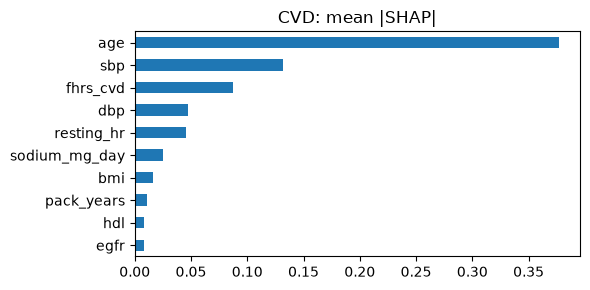

T2D   WARNING: the baseline goes the wrong way for hba1c (13 rows)
T2D   baseline chosen: no TreeSHAP (see the note in Cell 8)
CRD   WARNING: the baseline goes the wrong way for eosinophils (295 rows)
CRD   baseline chosen: no TreeSHAP (see the note in Cell 8)
NEURO top: phq9, sleep_hours_day, fhrs_neuro | top feature share 23%


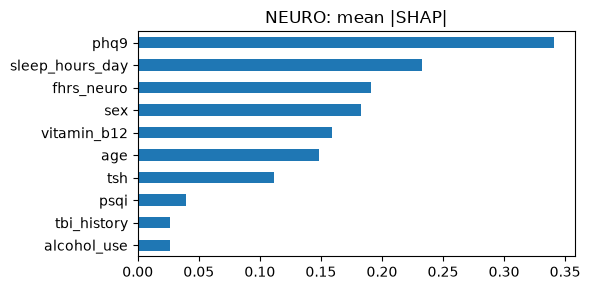

TEST Cell 7 (directions): PASS


In [8]:
# ---------- CODE ----------
def contributions(d, X):
    """SHAP values in log-odds, one column per feature (bias left out). XGBoost only."""
    booster = GBM[d].get_booster()
    return booster.predict(xgb.DMatrix(X, missing=np.nan, feature_names=list(X.columns)), pred_contribs=True)[:, :-1]

def wrong_directions(d, X, n=300, pfun=None):
    """Raise each +1 feature (10th -> 90th percentile): the risk must never go down (and -1 never up).
    pfun: another model's probability function (default: the chosen, calibrated model)."""
    pfun = pfun or (lambda Z: proba(d, Z))
    Xs, bad = X.sample(min(n, len(X)), random_state=SEED).reset_index(drop=True), []
    for col, sign in zip(feature_names(SPEC, d), directions(SPEC, d)):
        if sign == 0:
            continue
        lo, hi = np.nanpercentile(X[col], [10, 90])
        a, b = Xs.copy(), Xs.copy()
        a[col], b[col] = lo, hi
        diff = (pfun(b) - pfun(a)) * sign
        if (diff < -1e-9).any():
            bad.append(f"{col} ({int((diff < -1e-9).sum())} rows)")
    return bad

# ---------- RUN ----------
TOP = {}
for d in DISEASES:
    Xte = SPLITS[d]["test"][0]
    bad = wrong_directions(d, Xte)
    assert not bad, f"{d}: wrong direction {bad}"
    if CHOSEN[d] != "xgboost":
        print(f"{d:5s} baseline chosen: linear SHAP in the app, checked in Cell 8")
        continue
    c = contributions(d, Xte)
    imp = pd.Series(np.abs(c).mean(0), index=Xte.columns).sort_values(ascending=False)
    TOP[d] = list(imp.index[:3])
    share = imp.iloc[0] / imp.sum()
    print(f"{d:5s} top: {', '.join(TOP[d])} | top feature share {share:.0%}"
          + ("  <-- WARNING: one feature dominates, check for leakage" if share > 0.5 else ""))
    plt.figure(figsize=(6, 3)); imp.iloc[:10][::-1].plot.barh(); plt.title(f"{d}: mean |SHAP|"); plt.tight_layout(); plt.show()
print("TEST Cell 7 (directions): PASS")

## Cell 7b — XGBoost for all four diseases (comparison only)
XGBoost is now the chosen model for all four, so this repeats Cell 6 and Cell 7. It stays because `ml/investigate/auroc_ceiling.py` reads `metrics_xgb_all.csv`. Nothing here is saved as a model or registered.

In [9]:
# ---------- CODE ----------
CAL_XGB = {d: calibrate(GBM[d], *SPLITS[d]["val"][:2], d) for d in DISEASES}

def xgb_proba(d):
    return lambda X: CAL_XGB[d].predict_proba(X)[:, 1]

def xgb_row(d, X, y, where):
    p = xgb_proba(d)(X)
    r = {"disease": d, "data": where, "chosen": CHOSEN[d], "n": len(y), "pos": int(y.sum())}
    for name, fn in [("auroc", roc_auc_score), ("auprc", average_precision_score)]:
        lo, hi = boot_ci(y, p, fn)
        r[f"xgb_{name}"], r[f"xgb_{name}_ci"] = fn(y, p), f"{lo:.2f}-{hi:.2f}"
    r["xgb_calib_slope"] = calib_slope(y, p)
    return r

# ---------- RUN ----------
rows_x = []
for d in DISEASES:
    Xte, yte, _ = SPLITS[d]["test"]
    bad = wrong_directions(d, Xte, pfun=xgb_proba(d))
    rows_x.append({**xgb_row(d, Xte, yte, "test"), "xgb_wrong_directions": ", ".join(bad) or "none"})
    if TABLES2:
        X2, y2, _ = TABLES2[d]
        bad2 = wrong_directions(d, X2, pfun=xgb_proba(d))
        rows_x.append({**xgb_row(d, X2, y2, "seed2"), "xgb_wrong_directions": ", ".join(bad2) or "none"})
XGB_ALL = pd.DataFrame(rows_x)
XGB_ALL.to_csv(ART / "metrics_xgb_all.csv", index=False)

# ---------- TEST ----------
# XGBoost has the expected directions as monotone constraints and the calibration is monotone too
assert (XGB_ALL["xgb_wrong_directions"] == "none").all(), XGB_ALL[["disease", "data", "xgb_wrong_directions"]]
print("TEST Cell 7b: PASS (comparison only; the chosen model is unchanged)")
XGB_ALL.round(3)


TEST Cell 7b: PASS (comparison only; the chosen model is unchanged)


,disease,data,chosen,n,pos,xgb_auroc,xgb_auroc_ci,xgb_auprc,xgb_auprc_ci,xgb_calib_slope,xgb_wrong_directions
0,CVD,test,xgboost,2484,146,0.741,0.70-0.78,0.164,0.12-0.22,0.888,none
1,CVD,seed2,xgboost,16469,1008,0.733,0.72-0.75,0.157,0.14-0.17,0.908,none
2,T2D,test,baseline,2591,91,0.626,0.56-0.68,0.066,0.04-0.11,0.241,none
3,T2D,seed2,baseline,17243,632,0.674,0.65-0.70,0.069,0.06-0.08,0.525,none
4,CRD,test,baseline,2662,86,0.726,0.67-0.78,0.093,0.06-0.14,0.948,none
5,CRD,seed2,baseline,17687,564,0.742,0.72-0.76,0.085,0.07-0.10,0.624,none
6,NEURO,test,xgboost,2810,36,0.604,0.50-0.70,0.027,0.01-0.08,0.948,none
7,NEURO,seed2,xgboost,18672,247,0.601,0.57-0.64,0.020,0.02-0.03,0.938,none


## Cell 8 — Save one `.joblib` per disease + model card + SQL to register them
Then the **app's own loader** (`backend/model_registry.py`) opens each saved file and must give the same probabilities and SHAP values as this notebook. That proves the files work in the app before anyone registers them.

The printed **fingerprint** must be the same on every laptop (same data, seed and `uv.lock`).

In [10]:
# ---------- CODE ----------
# One version per run: model_versions has UNIQUE (disease_domain, version), so two runs on the same day
# must not share a version (register_models.sql would fail). varchar(30): '2026-11-05-150512' fits.
VERSION = datetime.now().strftime("%Y-%m-%d-%H%M%S")

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def fingerprint(d):
    """Short hash of the test predictions, rounded: the same on every laptop if the run is reproducible."""
    p = np.round(proba(d, SPLITS[d]["test"][0]), 6)
    return hashlib.sha256(p.tobytes()).hexdigest()[:12]

def save_all():
    saved = {}
    for d in DISEASES:
        path = ART / f"{d.lower()}.joblib"
        joblib.dump(CAL[d], path)
        saved[d] = {"path": f"ml/artifacts/{path.name}", "sha256": sha256(path)}
    return saved

def metrics_json(d):
    r = RESULTS[(RESULTS.disease == d) & (RESULTS.data == "test")].iloc[0]
    keep = ["auroc", "auprc", "brier", "brier_baseline", "calib_slope", "label_rate"]
    return {"model": CHOSEN[d], "calibration": "sigmoid" if d in PLATT_FOR else "isotonic",
            **{k: round(float(r[k]), 4) for k in keep}, "auroc_ci": r["auroc_ci"], "params": PARAMS[d],
            "seed": SEED, "versions": VERSIONS, "fingerprint": fingerprint(d)}

def register_sql(saved):
    """For Costin (database owner): run as postgres to register the models. Not run by the app."""
    lines = ["-- register_models.sql: made by ml/ai_model/train_models.ipynb. Run as postgres on med_db.",
             "-- Registers the new models and switches off the old ones, in one transaction.", "BEGIN;"]
    for d in DISEASES:
        cal = "sigmoid" if d in PLATT_FOR else "isotonic"
        algo = "XGBoost" if CHOSEN[d] == "xgboost" else "LogisticRegression"
        lines += [f"UPDATE public.model_versions SET is_active = false WHERE disease_domain = '{d}' AND is_active;",
                  "INSERT INTO public.model_versions (disease_domain, version, algorithm, artifact_path, artifact_sha256,",
                  "    feature_list, thresholds, calibration_method, metrics, trained_at, is_active)",
                  f"VALUES ('{d}', '{VERSION}', '{algo}', '{saved[d]['path']}', '{saved[d]['sha256']}',",
                  f"    '{json.dumps(feature_names(SPEC, d))}'::jsonb, '{json.dumps({'moderate': TIER_CUTS[0], 'high': TIER_CUTS[1]})}'::jsonb,",
                  f"    '{cal}', '{json.dumps(metrics_json(d))}'::jsonb, now(), true);"]
    lines.append("COMMIT;")
    (ART / "register_models.sql").write_text("\n".join(lines) + "\n", encoding="utf-8")

def write_model_card(saved):
    r = RESULTS[(RESULTS.data == "test") & (RESULTS.model != "baseline")].set_index("disease")
    lines = ["# Model card: CDSS risk models", "",
             f"- Version: {VERSION} | Seed: {SEED} | Data: synthetic (Notebook 1) | Packages: {VERSIONS}",
             "- Task: 5-year risk from the first visit, one binary model per disease",
             "- Split: 70/15/15 stratified by patient; 5-fold CV on train; calibration on validation; metrics on test", "",
             "| Disease | Model | Rows | Pos | AUROC (95% CI) | AUPRC | Brier | Slope | Flag | SHA-256 | Fingerprint |",
             "|---|---|---|---|---|---|---|---|---|---|---|"]
    for d in DISEASES:
        x = r.loc[d]
        lines.append(f"| {d} | {CHOSEN[d]} | {x.n} | {x.pos} | {x.auroc:.2f} ({x.auroc_ci}) | {x.auprc:.2f} | "
                     f"{x.brier:.3f} | {x.calib_slope:.2f} | {x.auroc_flag} | `{saved[d]['sha256'][:12]}` | `{fingerprint(d)}` |")
    lines += ["", f"## Features (features.yaml v{SPEC.get('version')}, {SPEC.get('status')})",
              *[f"- **{d}**: {', '.join(feature_names(SPEC, d))}" for d in DISEASES],
              "", "## Limits",
              "- Trained and tested on synthetic data; not proof of accuracy on real Filipino patients.",
              "- Must be re-checked on real, consented patient data before clinical use.",
              "- NEURO has few positives; its numbers are less certain.",
              "- Tier thresholds (0.20 / 0.50) come from the Data Dictionary, not tuned to this data."]
    (ART / "model_card.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

# ---------- TEST: the app's own loader gives the same answers ----------
def encoded_names(d):
    return [f["name"] for f in SPEC["models"][d]["features"] if "encoding" in f]

def as_app_inputs(row, d):
    """One row as the app's feature builder gives it: text features as text ("Male" / "Female"),
    so the test also proves that the app's encoding (features.yaml) is the one the model learned."""
    decode = {f["name"]: {float(v): k for k, v in f["encoding"].items()}
              for f in SPEC["models"][d]["features"] if "encoding" in f}
    out = {}
    for k, v in row.items():
        if pd.isna(v):
            out[k] = None
        elif k in decode:
            out[k] = decode[k][float(v)]
        else:
            out[k] = float(v)
    return out

def test_app_loads_the_files(saved):
    from backend import model_registry
    from backend.models import ModelVersion
    for d in DISEASES:
        row = ModelVersion(model_version_id=0, disease_domain=d, version=VERSION, artifact_path=saved[d]["path"],
                           artifact_sha256=saved[d]["sha256"], feature_list=feature_names(SPEC, d),
                           thresholds={"moderate": TIER_CUTS[0], "high": TIER_CUTS[1]}, metrics=metrics_json(d))
        app_model = model_registry.load_model(row)
        X = SPLITS[d]["test"][0]
        for i in range(0, len(X), max(1, len(X) // 25)):          # 25 test patients
            inputs = as_app_inputs(X.iloc[i], d)
            assert all(isinstance(inputs[n], str) for n in encoded_names(d) if inputs[n] is not None)
            assert abs(app_model.probability(inputs) - proba(d, X.iloc[[i]])[0]) < 1e-9, f"{d}: app probability differs"
            shap_app, base = app_model.contributions(inputs)
            if CHOSEN[d] == "xgboost":
                ours = contributions(d, X.iloc[[i]])[0]
                assert np.allclose([shap_app[c] for c in X.columns], ours, atol=1e-6), f"{d}: app SHAP differs"
            else:
                score = BASE[d].decision_function(X.iloc[[i]])[0]
                assert abs(sum(shap_app.values()) + base - score) < 1e-6, f"{d}: app SHAP does not add up"
        assert app_model.tier(0.2) == "Moderate" and app_model.tier(0.5) == "High"

# ---------- RUN ----------
SAVED = save_all()
write_model_card(SAVED)
register_sql(SAVED)
test_app_loads_the_files(SAVED)
if HAS_MLFLOW:                                   # local tracking in ml/mlruns/ (not committed)
    RUNS = ML / "mlruns"
    RUNS.mkdir(exist_ok=True)
    mlflow.set_tracking_uri(f"sqlite:///{(RUNS / 'mlflow.db').as_posix()}")   # MLflow 3: database, not plain files
    if mlflow.get_experiment_by_name("cdss-risk-models") is None:
        mlflow.create_experiment("cdss-risk-models", artifact_location=(RUNS / "artifacts").as_uri())
    mlflow.set_experiment("cdss-risk-models")
    for d in DISEASES:
        m = metrics_json(d)
        with mlflow.start_run(run_name=f"{d}-{VERSION}"):
            mlflow.log_params({"disease": d, "model": CHOSEN[d], "seed": SEED, **m["params"]})
            mlflow.log_metrics({k: m[k] for k in ("auroc", "auprc", "brier", "calib_slope")})
            mlflow.log_artifact(str(ART / f"{d.lower()}.joblib"))
print("TEST Cell 8: PASS (the app loads every file and gives the same answers)")
print("Fingerprints (must match on every laptop):", {d: fingerprint(d) for d in DISEASES})
print("Saved:", sorted(p.name for p in ART.iterdir() if p.suffix in (".joblib", ".md", ".sql", ".csv")))
if (RESULTS.auroc_flag == "LEAK?").any():
    print("\nWARNING: AUROC above 0.90 -> do NOT register these models yet. Do Phase 0 in Notebook 1 first.")

TEST Cell 8: PASS (the app loads every file and gives the same answers)
Fingerprints (must match on every laptop): {'CVD': '0f246f7a4e22', 'T2D': '499ff3981b3a', 'CRD': '0e333ee3dda4', 'NEURO': '331dcafd7a8d'}
Saved: ['crd.joblib', 'cvd.joblib', 'metrics.csv', 'metrics_xgb_all.csv', 'model_card.md', 'neuro.joblib', 'register_models.sql', 't2d.joblib']
